In [ ]:
!pip install -U yfinance curl_cffi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 3.7 MB/s eta 0:00:00
  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.66
    Uninstalling yfinance-0.2.66:
      Successfully uninstalled yfinance-0.2.66


In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("TensorFlow is working successfully!")

TensorFlow Version: 2.21.0
TensorFlow is working successfully!


In [ ]:

# LSTM DATA PREPARATION - BITCOIN PRICE PREDICTION

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler


# Download Bitcoin data


btc_data = yf.download(
    "BTC-USD",
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

btc_prices = btc_data["Close"].copy()

print("Number of Bitcoin records:", len(btc_prices))

# Convert to NumPy array

btc_values = btc_prices.values.reshape(-1, 1)

#Normalize Bitcoin prices

scaler = MinMaxScaler(feature_range=(0, 1))

btc_scaled = scaler.fit_transform(btc_values)

# Create 60-day sequences

sequence_length = 60

X = []
y = []

for i in range(sequence_length, len(btc_scaled)):
    X.append(btc_scaled[i-sequence_length:i, 0])
    y.append(btc_scaled[i, 0])

X = np.array(X)
y = np.array(y)

print("\nBefore Train-Test Split:")
print("X shape:", X.shape)
print("y shape:", y.shape)

#Train-Test Split

train_size = int(len(X) * 0.80)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

# Reshape data for LSTM
# LSTM requires: (samples, time steps, features)

X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

# Display results


print("\nAfter Train-Test Split:")
print("Training X shape:", X_train.shape)
print("Training y shape:", y_train.shape)

print("Testing X shape:", X_test.shape)
print("Testing y shape:", y_test.shape)

print("\nData preparation completed successfully!")

Number of Bitcoin records: 2192

Before Train-Test Split:
X shape: (2132, 60)
y shape: (2132,)

After Train-Test Split:
Training X shape: (1705, 60, 1)
Training y shape: (1705,)
Testing X shape: (427, 60, 1)
Testing y shape: (427,)

Data preparation completed successfully!


In [ ]:

# LSTM MODEL - BITCOIN PRICE PREDICTION
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Build the LSTM model
model = Sequential()

model.add(
    LSTM(
        50,
        return_sequences=True,
        input_shape=(X_train.shape[1], 1)
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(50, return_sequences=False)
)

model.add(Dropout(0.2))

model.add(Dense(25))
model.add(Dense(1))

 Compile the model

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

#Display model structure

model.summary()

# Train the model

history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=10,
    validation_data=(X_test, y_test),
    verbose=1
)

print("\nLSTM model training completed successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - loss: 0.0109 - val_loss: 0.0018
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0014 - val_loss: 0.0022
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0012 - val_loss: 0.0026
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.0011 - val_loss: 0.0040
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 9.8869e-04 - val_loss: 0.0016
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 9.5350e-04 - val_loss: 0.0021
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - loss: 8.3650e-04 - val_loss: 0.0021
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 8.8470e-04 - val_loss: 0.0068
Epoch 9/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 7.7877e-04 - val_loss: 0.0044
Epoch 10/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 7.1139e-04 - val_loss: 0.0024

LSTM model training completed successfully!


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step
Actual vs Predicted Bitcoin Prices
-----------------------------------
Actual: ₹70,215.19   Predicted: ₹67,923.61
Actual: ₹69,482.47   Predicted: ₹68,395.28
Actual: ₹69,289.27   Predicted: ₹68,709.18
Actual: ₹68,741.12   Predicted: ₹68,875.91
Actual: ₹67,811.51   Predicted: ₹68,888.83
Actual: ₹69,359.56   Predicted: ₹68,729.34
Actual: ₹75,639.08   Predicted: ₹68,582.11
Actual: ₹75,904.86   Predicted: ₹68,915.69
Actual: ₹76,545.48   Predicted: ₹69,559.78
Actual: ₹76,778.87   Predicted: ₹70,414.59


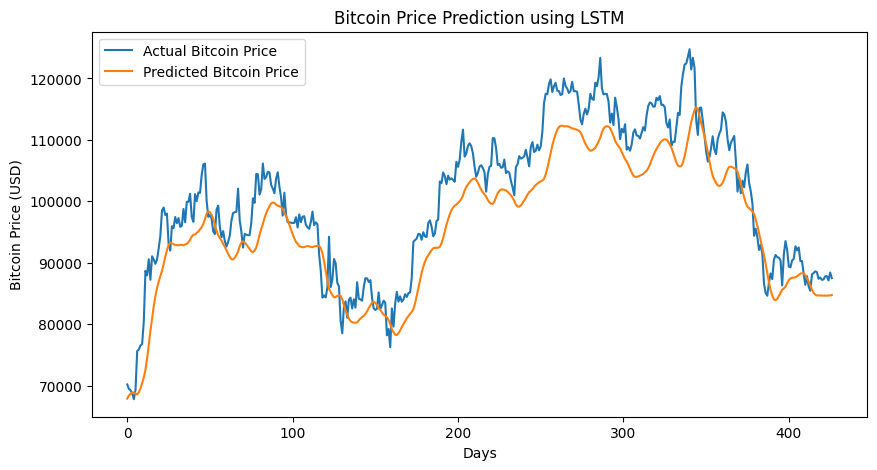

In [ ]:
# LSTM PREDICTION - ACTUAL VS PREDICTED BITCOIN PRICE

# Make predictions
predictions = model.predict(X_test)

# Convert predictions back to original Bitcoin price
predicted_prices = scaler.inverse_transform(predictions)

# Convert actual values back to original Bitcoin price
actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)
# Display first 10 predictions
print("Actual vs Predicted Bitcoin Prices")
print("-----------------------------------")

for i in range(10):
    print(
        f"Actual: ₹{actual_prices[i][0]:,.2f}   "
        f"Predicted: ₹{predicted_prices[i][0]:,.2f}"
    )
# Plot Actual vs Predicted prices

plt.figure(figsize=(10, 5))

plt.plot(
    actual_prices,
    label="Actual Bitcoin Price"
)

plt.plot(
    predicted_prices,
    label="Predicted Bitcoin Price"
)

plt.title("Bitcoin Price Prediction using LSTM")
plt.xlabel("Days")
plt.ylabel("Bitcoin Price (USD)")
plt.legend()

plt.show()

In [ ]:
# LSTM MODEL EVALUATION

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE
mae = mean_absolute_error(
    actual_prices,
    predicted_prices
)

# Calculate RMSE
rmse = np.sqrt(
    mean_squared_error(
        actual_prices,
        predicted_prices
    )
)

print("LSTM MODEL EVALUATION")
print("---------------------")
print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")

LSTM MODEL EVALUATION
---------------------
MAE  : 4,948.02
RMSE : 5,857.66


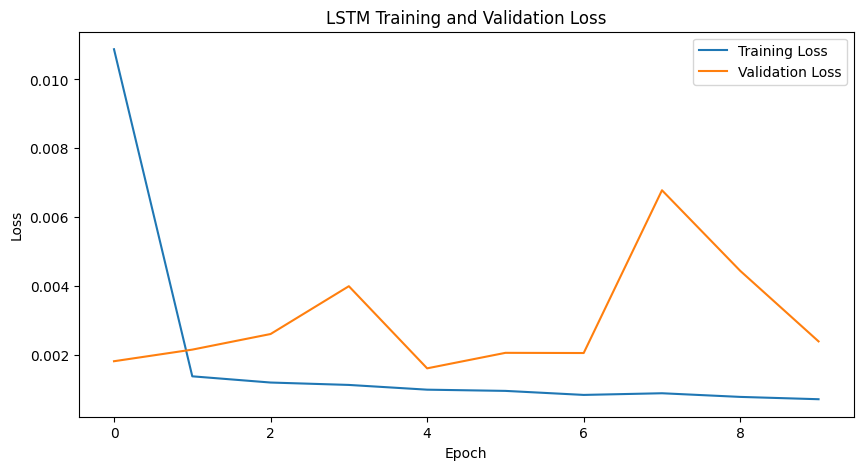

In [ ]:
# LSTM TRAINING LOSS GRAPH
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:

import yfinance as yf
import pandas as pd

assets = [
    "BTC-USD",
    "ETH-USD",
    "AAPL",
    "MSFT",
    "NVDA",
    "GLD",
    "TLT"
]

data = yf.download(
    assets,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

prices = data["Close"]

# Remove rows where all assets have missing prices
prices = prices.dropna(how="all")

print("Dataset downloaded successfully!")
print("Dataset shape:", prices.shape)
display(prices.head())

Dataset downloaded successfully!
Dataset shape: (2192, 7)


Ticker,AAPL,BTC-USD,ETH-USD,GLD,MSFT,NVDA,TLT
Date,,,,,,,
2020-01-01,NaN,7200.174316,130.802002,NaN,NaN,NaN,NaN
2020-01-02,72.271545,6985.470215,127.410179,143.949997,151.544250,5.957138,111.552551
2020-01-03,71.568916,7344.884277,134.171707,145.860001,149.657272,5.861788,113.270561
2020-01-04,NaN,7410.656738,135.069366,NaN,NaN,NaN,NaN
2020-01-05,NaN,7411.317383,136.276779,NaN,NaN,NaN,NaN


In [ ]:

returns = prices.pct_change()
volatility = returns.rolling(window=7).std()

features = pd.concat(
    [
        returns.add_suffix("_return"),
        volatility.add_suffix("_volatility")
    ],
    axis=1
)

features = features.replace([np.inf, -np.inf], np.nan)
features = features.dropna()

print("Feature dataset shape:", features.shape)
display(features.head())

Feature dataset shape: (2184, 14)


/tmp/ipykernel_708/4282990530.py:1: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = prices.pct_change()


Ticker,AAPL_return,BTC-USD_return,ETH-USD_return,GLD_return,MSFT_return,NVDA_return,TLT_return,AAPL_volatility,BTC-USD_volatility,ETH-USD_volatility,GLD_volatility,MSFT_volatility,NVDA_volatility,TLT_volatility
Date,,,,,,,,,,,,,,
2020-01-09,0.021241,-0.024851,-0.016133,-0.005652,0.012493,0.010983,0.003511,0.011210,0.032011,0.031059,0.007741,0.010343,0.009307,0.007629
2020-01-10,0.002261,0.036487,0.035866,0.006026,-0.004627,0.005350,0.008891,0.009472,0.029812,0.027867,0.006357,0.008930,0.004946,0.005601
2020-01-11,0.000000,-0.015798,-0.007201,0.000000,0.000000,0.000000,0.000000,0.009472,0.032116,0.028662,0.006357,0.008930,0.004946,0.005601
2020-01-12,0.000000,0.019279,0.020618,0.000000,0.000000,0.000000,0.000000,0.009472,0.031736,0.029033,0.006357,0.008930,0.004946,0.005601
2020-01-13,0.021364,-0.005896,-0.011293,-0.007419,0.012024,0.031352,-0.003034,0.011118,0.028679,0.020134,0.005462,0.009635,0.011098,0.005288


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Autoencoder libraries imported successfully!")

Autoencoder libraries imported successfully!


In [ ]:

# Number of input features
input_dim = X_train.shape[1]

# Encoder
input_layer = Input(shape=(input_dim,))
encoded = Dense(32, activation="relu")(input_layer)
encoded = Dropout(0.1)(encoded)
encoded = Dense(16, activation="relu")(encoded)
encoded = Dense(8, activation="relu")(encoded)

# Decoder
decoded = Dense(16, activation="relu")(encoded)
decoded = Dense(32, activation="relu")(decoded)
output_layer = Dense(input_dim, activation="linear")(decoded)

# Create Autoencoder
autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

# Compile model
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Display model architecture
autoencoder.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 60)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 60)             │         1,980 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,284 (20.64 KB)

 Trainable params: 5,284 (20.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train,
    X_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Autoencoder training completed!")

Epoch 1/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0368 - val_loss: 0.0655
Epoch 2/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0072 - val_loss: 0.0053
Epoch 3/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0034 - val_loss: 0.0028
Epoch 4/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0025 - val_loss: 0.0032
Epoch 5/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0020 - val_loss: 0.0033
Epoch 6/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0020 - val_loss: 0.0026
Epoch 7/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0018 - val_loss: 0.0029
Epoch 8/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0017 - val_loss: 0.0028
Epoch 9/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 10/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0017 - val_loss: 0.0029
Epoch 11/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0016 - val_loss: 0.0032
Autoencoder training completed!


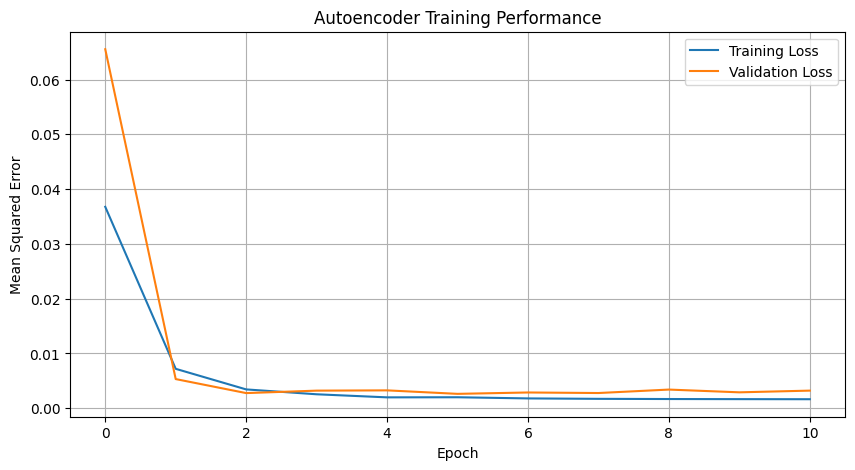

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

# Create separate Autoencoder variables
ae_split = int(len(features) * 0.80)

ae_train_data = features.iloc[:ae_split]
ae_test_data = features.iloc[ae_split:]

ae_scaler = StandardScaler()

ae_X_train = ae_scaler.fit_transform(ae_train_data)
ae_X_test = ae_scaler.transform(ae_test_data)

print("Autoencoder training shape:", ae_X_train.shape)
print("Autoencoder testing shape:", ae_X_test.shape)


Autoencoder training shape: (1747, 14)
Autoencoder testing shape: (437, 14)


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Number of input features
input_dim = ae_X_train.shape[1]

# Build Autoencoder
input_layer = Input(shape=(input_dim,))

encoder = Dense(32, activation="relu")(input_layer)
encoder = Dense(16, activation="relu")(encoder)
encoded = Dense(8, activation="relu")(encoder)

decoder = Dense(16, activation="relu")(encoded)
decoder = Dense(32, activation="relu")(decoder)
decoded = Dense(input_dim, activation="linear")(decoder)

autoencoder = Model(input_layer, decoded)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 14)             │           462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,294 (8.96 KB)

 Trainable params: 2,294 (8.96 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    ae_X_train,
    ae_X_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Autoencoder training completed successfully!")

Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.0295 - val_loss: 0.6031
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9762 - val_loss: 0.5767
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8722 - val_loss: 0.5055
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7290 - val_loss: 0.4445
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6257 - val_loss: 0.4011
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5624 - val_loss: 0.3831
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5238 - val_loss: 0.3710
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5000 - val_loss: 0.3618
Epoch 9/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4793 - val_loss: 0.3523
Epoch 10/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4565 - val_loss: 0.3383
Epoch 11/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4284 - val_loss: 0.3211
Epoch 12/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4022 - val_lo

In [ ]:
#Reconstruction and Anomaly detection step
import numpy as np

# Reconstruct training and testing data
train_reconstructed = autoencoder.predict(ae_X_train, verbose=0)
test_reconstructed = autoencoder.predict(ae_X_test, verbose=0)

# Calculate mean squared reconstruction error
train_errors = np.mean(
    np.square(ae_X_train - train_reconstructed), axis=1
)

test_errors = np.mean(
    np.square(ae_X_test - test_reconstructed), axis=1
)

# Set anomaly threshold using the 95th percentile of training errors
threshold = np.percentile(train_errors, 95)

print("Anomaly threshold:", threshold)
print("Average training reconstruction error:", np.mean(train_errors))
print("Average testing reconstruction error:", np.mean(test_errors))
print("Reconstruction errors calculated successfully!")


Anomaly threshold: 0.42562884751749536
Average training reconstruction error: 0.15177890147819065
Average testing reconstruction error: 0.19855195818464388
Reconstruction errors calculated successfully!


In [ ]:
#Detecting Potential anamalies

import pandas as pd

# Create anomaly results for the test period
anomalies = pd.DataFrame(index=ae_test_data.index)

anomalies["Reconstruction_Error"] = test_errors
anomalies["Anomaly"] = test_errors > threshold

# Display summary
print("Total test observations:", len(anomalies))
print("Detected anomalies:", int(anomalies["Anomaly"].sum()))

# Display first 10 detected anomalies
display(anomalies[anomalies["Anomaly"]].head(10))


Total test observations: 437
Detected anomalies: 48


,Reconstruction_Error,Anomaly
Date,,
2024-10-31,0.531154,True
2024-11-25,1.334981,True
2025-01-27,2.065586,True
2025-01-29,0.448074,True
2025-01-30,0.813734,True
2025-01-31,0.464408,True
2025-03-03,0.587555,True
2025-04-03,1.006104,True
2025-04-04,0.830361,True


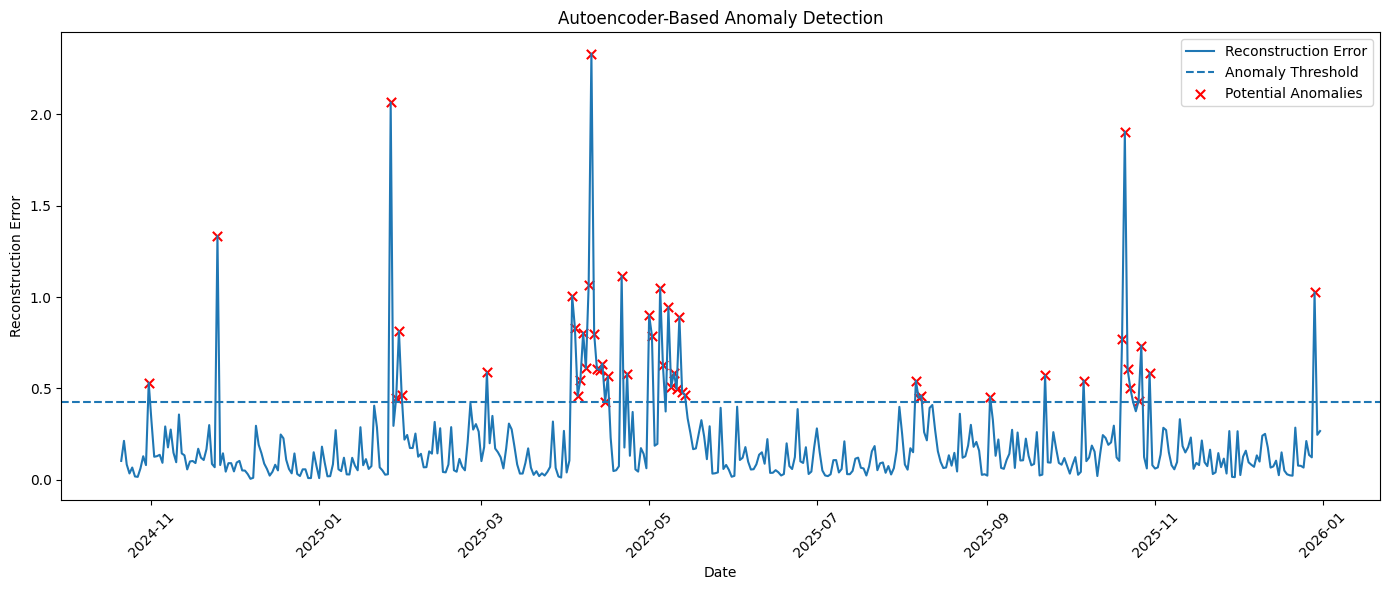

In [ ]:
#Plotting Graph of Detected Anamoly

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Plot reconstruction errors
plt.plot(
    anomalies.index,
    anomalies["Reconstruction_Error"],
    label="Reconstruction Error",
    linewidth=1.5
)

# Plot anomaly threshold
plt.axhline(
    y=threshold,
    linestyle="--",
    label="Anomaly Threshold"
)

# Highlight detected anomalies
detected = anomalies[anomalies["Anomaly"]]

plt.scatter(
    detected.index,
    detected["Reconstruction_Error"],
    color="red",
    marker="x",
    s=45,
    label="Potential Anomalies"
)

plt.title("Autoencoder-Based Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Save anomaly detection results to CSV
output_file = "Autoencoder_Anomaly_Results.csv"

anomalies.to_csv(output_file, index_label="Date")

print("Anomaly results saved successfully:", output_file)

# Download the CSV file
from google.colab import files
files.download(output_file)

Anomaly results saved successfully: Autoencoder_Anomaly_Results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>